## Let's practice the concepts from the previous notebook!!!

In [40]:
print("Let's start!!!")

Let's start!!!


## 1. Importing libraries

In [41]:
import torch
from torch import nn # neural network building blocks
import matplotlib.pyplot as plt # data visualization
import numpy as np

print("Torch Library Version: ", torch.__version__)

Torch Library Version:  2.11.0+cpu


## 2. Setting a device agnostic environment

In [42]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Current Device: ", device)

Current Device:  cpu


## 3. Linear Regression Datasets Creation

In [43]:
# hard-coded parameters
weight = 0.7
bias = 0.3

# hard-coded range values
start_val = 0
end_val = 1
step_val = 0.02

# dataset values display function (added by me)
def display_dataset_values(dataset: torch, values_num=None):
  if values_num is None:
    values_num = len(dataset)

  if values_num > len(dataset):
    values_num = len(dataset)

  for i in range(values_num):
    print(f"{i + 1}: {dataset[i]}")

# features dataset (X) - column vector
X = torch.arange(start=start_val, end=end_val, step=step_val).unsqueeze(dim=1)
print("Linear Regression Features Dataset (first 15 elements):")
display_dataset_values(X, 15)

# labels dataset (y) - column vector
y = weight * X + bias
print("Linear Regression Labels Dataset (first 15 elements):")
display_dataset_values(y, 15)

Linear Regression Features Dataset (first 15 elements):
1: tensor([0.])
2: tensor([0.0200])
3: tensor([0.0400])
4: tensor([0.0600])
5: tensor([0.0800])
6: tensor([0.1000])
7: tensor([0.1200])
8: tensor([0.1400])
9: tensor([0.1600])
10: tensor([0.1800])
11: tensor([0.2000])
12: tensor([0.2200])
13: tensor([0.2400])
14: tensor([0.2600])
15: tensor([0.2800])
Linear Regression Labels Dataset (first 15 elements):
1: tensor([0.3000])
2: tensor([0.3140])
3: tensor([0.3280])
4: tensor([0.3420])
5: tensor([0.3560])
6: tensor([0.3700])
7: tensor([0.3840])
8: tensor([0.3980])
9: tensor([0.4120])
10: tensor([0.4260])
11: tensor([0.4400])
12: tensor([0.4540])
13: tensor([0.4680])
14: tensor([0.4820])
15: tensor([0.4960])


## 4. Splitting the datasets intro training and testing datasets

In [44]:
# hard-coded training datasets percentage
train_split_percentage = 0.8

train_split = int(train_split_percentage * len(X))

X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

print(f"X_train length: {len(X_train)}")
print(f"y_train length: {len(y_train)}")
print(f"X_test length: {len(X_test)}")
print(f"y_test length: {len(y_test)}")

X_train length: 40
y_train length: 40
X_test length: 10
y_test length: 10


## 5. Visualize the Datasets

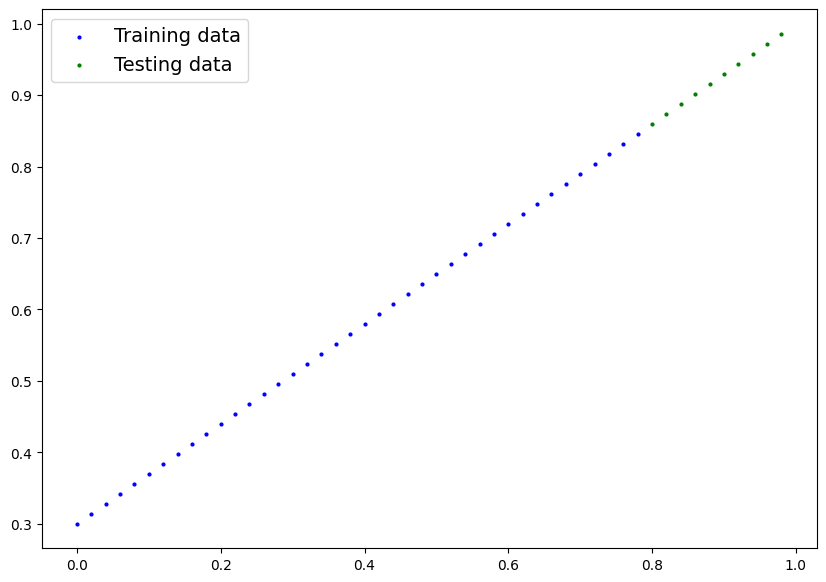

In [45]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

plot_predictions(X_train, y_train, X_test, y_test)

## 6. Creating the Linear Regression Model (nn.Parameter)

In [46]:
class LinearRegressionModelV1(nn.Module):
  def __init__(self):
    super().__init__()

    # initialize model parameters (nn.Parameter)
    self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))
    self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))

  # forward method
  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias

## 7. Creating the Linear Regression Model (nn.Linear)

In [47]:
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()

    # initialize model parameters (nn.Linear)
    self.linear_layer = nn.Linear(in_features=1, out_features=1)

  # forward method
  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)

## 8. Linear Regression Model Instances

In [48]:
torch.manual_seed(42) # parameters value remain the same after running this cell for multiple times

model_1 = LinearRegressionModelV1()
model_2 = LinearRegressionModelV2()

print(f"Model 1 Details:")
print(model_1)

print(f"Model 1 State Dictionary:")
print(model_1.state_dict())

print(f"Model 2 Details:")
print(model_2)

print(f"Model 2 State Dictionary:")
print(model_2.state_dict())

Model 1 Details:
LinearRegressionModelV1()
Model 1 State Dictionary:
OrderedDict({'weights': tensor([0.3367]), 'bias': tensor([0.1288])})
Model 2 Details:
LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)
Model 2 State Dictionary:
OrderedDict({'linear_layer.weight': tensor([[-0.2191]]), 'linear_layer.bias': tensor([0.2018])})


## 9. Current Device Setup - Model 1 (nn.Parameter)

In [49]:
# check model device
next(model_1.parameters()).device

device(type='cpu')

In [50]:
model_1.to(device)
next(model_1.parameters()).device

device(type='cpu')

## 10. Training and Testing Loop - Model 1 (nn.Parameter)
#### Loss Function: https://www.geeksforgeeks.org/deep-learning/loss-functions-in-deep-learning/

#### Optimizer: https://www.geeksforgeeks.org/deep-learning/optimization-rule-in-deep-neural-networks/

#### The Main Ideas of Least Squares and Linear Regression: https://youtu.be/PaFPbb66DxQ?si=OIcRxgsLWY5v7I67

#### Gradient Descent: https://youtu.be/sDv4f4s2SB8?si=aQ-U0X2IKRqGNS3b

#### Stochastic Gradient Descent: https://youtu.be/vMh0zPT0tLI?si=uVKe6OGI6iZxRmMI

#### Neural Network Essential Ideas (Part. 1): https://youtu.be/CqOfi41LfDw?si=EUs36ar7RsucubLG

#### Chain Rule: https://youtu.be/wl1myxrtQHQ?si=JoF-1HYBMl16-Ko1

#### Neural Network Essential Ideas (Part. 2): https://youtu.be/IN2XmBhILt4?si=w3UK2Ro6vcfP-w13

#### Backpropagation Details (Part. 1): https://youtu.be/iyn2zdALii8?si=v8HocPeVM0sBx8yk

#### Backpropagation Details (Part. 2): https://youtu.be/GKZoOHXGcLo?si=8QyccRGpJwgt-4Bq

In [51]:
# create loss function (mean absolute error)
loss_fn = nn.L1Loss()

# create optimizer (stochastic gradient descedent)
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)

In [52]:
torch.manual_seed(42) # reproducibility

epochs = 1000 # number of training iterations

# put data on the available device
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

train_loss_values, test_loss_values = [], []

# training and testing loop
for epoch in range(epochs):
    model_1.train() # train mode

    # 1.a forward pass
    train_pred = model_1(X_train)

    # 1.b calculate loss
    train_loss = loss_fn(train_pred, y_train)
    train_loss_values.append(train_loss)

    # 1.c zero gradients
    optimizer.zero_grad()

    # 1.d loss backward
    train_loss.backward()

    # 1.e step the optimizer
    optimizer.step()

    model_1.eval() # evaluation mode (inference mode)

    with torch.inference_mode():
        # 2.a forward pass
        test_pred = model_1(X_test)
    
        # 2.b calculate loss
        test_loss = loss_fn(test_pred, y_test)
        test_loss_values.append(test_loss)

In [53]:
epochs = 10

# Header for readability
print(f"{'Epoch':>5} | {'Train Loss':>12} | {'Test Loss':>11}")
print("-" * 38)

for epoch in range(epochs):
    train = train_loss_values[epoch]
    test  = test_loss_values[epoch]
    # ``{value:12.5f} --> total width 12, 5 digits after the decimal point
    print(f"{epoch:5d} | {train:12.5f} | {test:11.5f}")

Epoch |   Train Loss |   Test Loss
--------------------------------------
    0 |      0.31288 |     0.48107
    1 |      0.30136 |     0.46759
    2 |      0.28984 |     0.45412
    3 |      0.27832 |     0.44065
    4 |      0.26680 |     0.42718
    5 |      0.25528 |     0.41371
    6 |      0.24376 |     0.40024
    7 |      0.23223 |     0.38677
    8 |      0.22071 |     0.37330
    9 |      0.20919 |     0.35983


In [54]:
epochs = len(train_loss_values)

# Header for readability
print(f"{'Epoch':>5} | {'Train Loss':>12} | {'Test Loss':>11}")
print("-" * 38)

for epoch in range(10, epochs, 10):
    train = train_loss_values[epoch]
    test  = test_loss_values[epoch]
    # {value:12.5f} → total width 12, 5 digits after the decimal point
    print(f"{epoch:5d} | {train:12.5f} | {test:11.5f}")

Epoch |   Train Loss |   Test Loss
--------------------------------------
   10 |      0.19767 |     0.34636
   20 |      0.08909 |     0.21730
   30 |      0.05315 |     0.14464
   40 |      0.04544 |     0.11361
   50 |      0.04168 |     0.09920
   60 |      0.03819 |     0.08887
   70 |      0.03476 |     0.08059
   80 |      0.03132 |     0.07232
   90 |      0.02789 |     0.06474
  100 |      0.02446 |     0.05646
  110 |      0.02102 |     0.04819
  120 |      0.01759 |     0.04060
  130 |      0.01416 |     0.03233
  140 |      0.01072 |     0.02406
  150 |      0.00728 |     0.01647
  160 |      0.00385 |     0.00820
  170 |      0.00893 |     0.00502
  180 |      0.00893 |     0.00502
  190 |      0.00893 |     0.00502
  200 |      0.00893 |     0.00502
  210 |      0.00893 |     0.00502
  220 |      0.00893 |     0.00502
  230 |      0.00893 |     0.00502
  240 |      0.00893 |     0.00502
  250 |      0.00893 |     0.00502
  260 |      0.00893 |     0.00502
  270 |      0.0

In [55]:
# Model 1 (nn.Parameter) learned parameters
from pprint import pprint # pprint = pretty print, see: https://docs.python.org/3/library/pprint.html
print("The model learned the following values for weights and bias:")
pprint(model_1.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict({'weights': tensor([0.6990]), 'bias': tensor([0.3093])})

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


## 11. Training and Testing Loop - Model 2 (nn.Linear)

In [56]:
# create loss function (mean absolute error)
loss_fn = nn.L1Loss()

# create optimizer (stochastic gradient descedent)
optimizer = torch.optim.SGD(params=model_2.parameters(), lr=0.01)

In [57]:
torch.manual_seed(42) # reproducibility

epochs = 1000 # number of training iterations

# put data on the available device
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

train_loss_values, test_loss_values = [], []

# training loop
for epoch in range(epochs):
    model_2.train() # train mode

    # 1.a forward pass
    train_pred = model_2(X_train)

    # 1.b calculate loss
    train_loss = loss_fn(train_pred, y_train)
    train_loss_values.append(train_loss)

    # 1.c zero gradients
    optimizer.zero_grad()

    # 1.d loss backward
    train_loss.backward()

    # 1.e step the optimizer
    optimizer.step()

    # testing loop
    model_2.eval() # evaluation mode (inference mode)

    with torch.inference_mode():
        # 2.a forward pass
        test_pred = model_2(X_test)
    
        # 2.b calculate loss
        test_loss = loss_fn(test_pred, y_test)
        test_loss_values.append(test_loss)

In [58]:
epochs = 10

# Header for readability
print(f"{'Epoch':>5} | {'Train Loss':>12} | {'Test Loss':>11}")
print("-" * 38)

for epoch in range(epochs):
    train = train_loss_values[epoch]
    test  = test_loss_values[epoch]
    # {value:12.5f} → total width 12, 5 digits after the decimal point
    print(f"{epoch:5d} | {train:12.5f} | {test:11.5f}")

Epoch |   Train Loss |   Test Loss
--------------------------------------
    0 |      0.45666 |     0.90274
    1 |      0.44514 |     0.88927
    2 |      0.43362 |     0.87580
    3 |      0.42210 |     0.86233
    4 |      0.41058 |     0.84886
    5 |      0.39905 |     0.83539
    6 |      0.38753 |     0.82191
    7 |      0.37601 |     0.80844
    8 |      0.36449 |     0.79497
    9 |      0.35297 |     0.78150


In [59]:
epochs = len(train_loss_values)

# Header for readability
print(f"{'Epoch':>5} | {'Train Loss':>12} | {'Test Loss':>11}")
print("-" * 38)

for epoch in range(10, epochs, 10):
    train = train_loss_values[epoch]
    test  = test_loss_values[epoch]
    # {value:12.5f} → total width 12, 5 digits after the decimal point
    print(f"{epoch:5d} | {train:12.5f} | {test:11.5f}")

Epoch |   Train Loss |   Test Loss
--------------------------------------
   10 |      0.34154 |     0.76853
   20 |      0.25481 |     0.65181
   30 |      0.20336 |     0.55965
   40 |      0.17334 |     0.48786
   50 |      0.15609 |     0.43376
   60 |      0.14575 |     0.39294
   70 |      0.13898 |     0.36252
   80 |      0.13399 |     0.33870
   90 |      0.12999 |     0.32090
  100 |      0.12623 |     0.30649
  110 |      0.12274 |     0.29547
  120 |      0.11925 |     0.28445
  130 |      0.11576 |     0.27343
  140 |      0.11227 |     0.26241
  150 |      0.10882 |     0.25345
  160 |      0.10538 |     0.24586
  170 |      0.10195 |     0.23759
  180 |      0.09851 |     0.22932
  190 |      0.09508 |     0.22173
  200 |      0.09165 |     0.21346
  210 |      0.08821 |     0.20519
  220 |      0.08478 |     0.19760
  230 |      0.08134 |     0.18933
  240 |      0.07790 |     0.18174
  250 |      0.07448 |     0.17347
  260 |      0.07104 |     0.16520
  270 |      0.0

In [60]:
# Model 2 (nn.Linear) learned parameters
from pprint import pprint # pprint = pretty print, see: https://docs.python.org/3/library/pprint.html
print("The model learned the following values for weights and bias:")
pprint(model_2.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict([('linear_layer.weight', tensor([[0.6943]])),
             ('linear_layer.bias', tensor([0.2988]))])

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


## 12. Making Predictions - Model 1 (nn.Parameter)

In [61]:
# Turn model into evaluation mode
model_1.eval()

# Make predictions on the test data
with torch.inference_mode():
    y_preds = model_1(X_test)
    
y_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

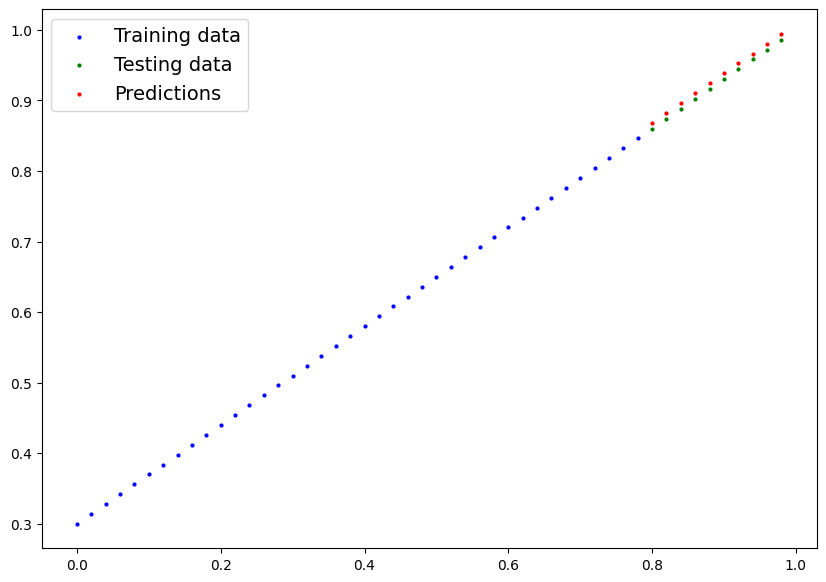

In [62]:
# plot_predictions(predictions=y_preds) # -> won't work... data not on CPU

# Put data on the CPU and plot it
plot_predictions(predictions=y_preds.cpu())

## 13. Making Predictions - Model 2 (nn.Linear)

In [63]:
# Turn model into evaluation mode
model_2.eval()

# Make predictions on the test data
with torch.inference_mode():
    y_preds = model_2(X_test)
    
y_preds

tensor([[0.8542],
        [0.8681],
        [0.8820],
        [0.8959],
        [0.9097],
        [0.9236],
        [0.9375],
        [0.9514],
        [0.9653],
        [0.9792]])

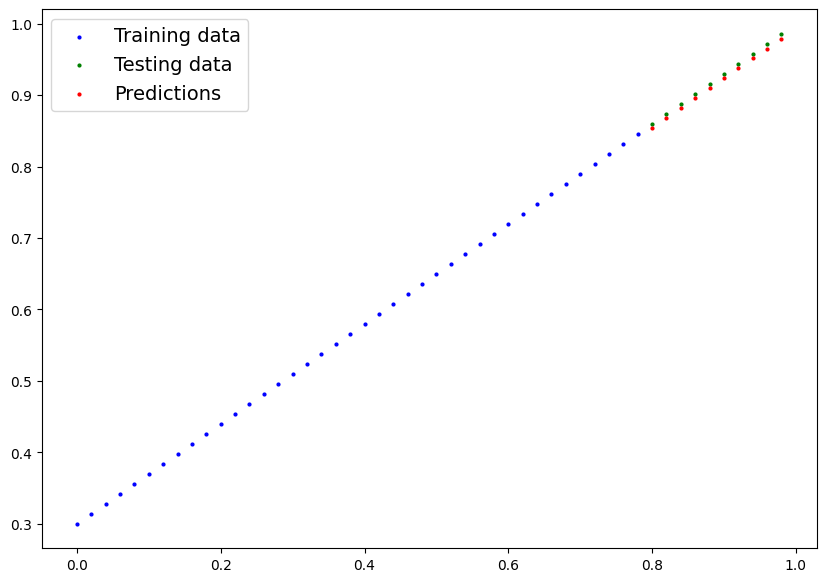

In [64]:
# plot_predictions(predictions=y_preds) # -> won't work... data not on CPU

# Put data on the CPU and plot it
plot_predictions(predictions=y_preds.cpu())

## 14. Saving - Model 1 (nn.Parameter)

In [65]:
from pathlib import Path

# 1.a create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 1.b create model save path
MODEL_NAME_01 = "01_pytorch_worflow_model_1.pth"
MODEL_SAVE_PATH_01 = MODEL_PATH / MODEL_NAME_01

# 1.c save the model state dictionary
print(f"Saving Model 1 (nn.Parameter) to: {MODEL_SAVE_PATH_01}\n")
print(f"Model 1 State Dictionary: {model_1.state_dict()}\n")
torch.save(obj=model_1.state_dict(), f=MODEL_SAVE_PATH_01)
print(f"Model 1 (nn.Parameter) saved to: {MODEL_SAVE_PATH_01}\n")


Saving Model 1 (nn.Parameter) to: models/01_pytorch_worflow_model_1.pth

Model 1 State Dictionary: OrderedDict({'weights': tensor([0.6990]), 'bias': tensor([0.3093])})

Model 1 (nn.Parameter) saved to: models/01_pytorch_worflow_model_1.pth



## 15. Saving - Model 2 (nn.Linear)

In [66]:
# 2.a create model save path
MODEL_NAME_02 = "01_pytorch_worflow_model_2.pth"
MODEL_SAVE_PATH_02 = MODEL_PATH / MODEL_NAME_02

# 2.b save the model state dictionary
print(f"Saving Model 2 (nn.Linear) to: {MODEL_SAVE_PATH_02}\n")
print(f"Model 2 State Dictionary: {model_2.state_dict()}\n")
torch.save(obj=model_2.state_dict(), f=MODEL_SAVE_PATH_02)
print(f"Model 2 (nn.Linear) saved to: {MODEL_SAVE_PATH_02}\n")


Saving Model 2 (nn.Linear) to: models/01_pytorch_worflow_model_2.pth

Model 2 State Dictionary: OrderedDict({'linear_layer.weight': tensor([[0.6943]]), 'linear_layer.bias': tensor([0.2988])})

Model 2 (nn.Linear) saved to: models/01_pytorch_worflow_model_2.pth



#### Claude Debugging

In [67]:
import os, sys, platform
from pathlib import Path

print("Python:   ", sys.executable)
print("OS:       ", platform.platform())
print("CWD:      ", os.getcwd())
print("Salvat la:", Path("models/01_pytorch_worflow_model_1.pth").resolve())
print("Există:   ", Path("models/01_pytorch_worflow_model_1.pth").exists())


Python:    /usr/bin/python3
OS:        Linux-6.6.159+-x86_64-with-glibc2.39
CWD:       /content
Salvat la: /content/models/01_pytorch_worflow_model_1.pth
Există:    True


### The Problem: The models are saved in Google Colab, not locally.

In [68]:
import sys
print(sys.executable)
print(sys.prefix)


/usr/bin/python3
/usr


### Temporary Solution: I manually downloaded the models from my drive account.

# 16.a Loading - Model 1 (nn.Parameter)

In [ ]:
# The Loading Process
loaded_model_1 = LinearRegressionModelV1()

loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH_01))

loaded_model_1.to(device)

print(f"Loaded model: {loaded_model_1}")
print(f"Model on device: {next(loaded_model_1.parameters()).device}")
print(f"Loaded Model parameters:\n{list(loaded_model_1.parameters())}")

Loaded model: LinearRegressionModelV1()
Model on device: cpu
Loaded Model parameters:
[Parameter containing:
tensor([0.6990], requires_grad=True), Parameter containing:
tensor([0.3093], requires_grad=True)]


# 16.b Loading - Model 1 (nn.Parameter)

In [ ]:
# The Loaded Model Parameters Evaluation Process
print(f"Original Model parameters:\n{list(model_1.parameters())}\n")
print(f"Loaded Model parameters:\n{list(loaded_model_1.parameters())}\n")

loading_condition = all(
    torch.equal(p1, p2) 
    for p1, p2 in zip(model_1.state_dict().values(), loaded_model_1.state_dict().values())
)

message = "Model 1 was succesfully loaded!" if loading_condition else "Model 1 was not succesfully loaded!"

print(f"MESSAGE: {message}")

Original Model parameters:
[Parameter containing:
tensor([0.6990], requires_grad=True), Parameter containing:
tensor([0.3093], requires_grad=True)]

Loaded Model parameters:
[Parameter containing:
tensor([0.6990], requires_grad=True), Parameter containing:
tensor([0.3093], requires_grad=True)]

MESSAGE: Model 1 was succesfully loaded!


# 16.c Loading - Model 1 (nn.Parameter)

In [91]:
# The Loaded Model Inference Evaluation Process

model_1.eval(), loaded_model_1.eval()

with torch.inference_mode():
    original_model_pred_01 = model_1(X_test)
    loaded_model_pred_01 = loaded_model_1(X_test)

message = "SUCCESS: The loaded model inference matches the original model inference!" if loading_condition else "FAILURE: The loaded model inference does not match the original model inference!"

print(message)

SUCCESS: The loaded model inference matches the original model inference!


# 17.a Loading - Model 2 (nn.Linear)

In [94]:
# The Loading Process
loaded_model_2 = LinearRegressionModelV2()

loaded_model_2.load_state_dict(torch.load(MODEL_SAVE_PATH_02))

loaded_model_2.to(device)

print(f"Loaded model (nn.Linear):\n{loaded_model_2}")
print(f"Model on device: {next(loaded_model_2.parameters()).device}")
print(f"Loaded Model parameters:\n{list(loaded_model_2.parameters())}")

Loaded model (nn.Linear):
LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)
Model on device: cpu
Loaded Model parameters:
[Parameter containing:
tensor([[0.6943]], requires_grad=True), Parameter containing:
tensor([0.2988], requires_grad=True)]


# 17.b Loading - Model 2 (nn.Linear)

In [97]:
# The Loaded Model Parameters Evaluation Process
print(f"Original Model parameters:\n{list(model_2.parameters())}\n")
print(f"Loaded Model parameters:\n{list(loaded_model_2.parameters())}\n")

loading_condition = all(
    torch.equal(p1, p2) 
    for p1, p2 in zip(model_2.state_dict().values(), loaded_model_2.state_dict().values())
)

message = "SUCCES: The loaded model parameters match the original model parameters!" if loading_condition else "FAILURE: The loaded model parameters do not match the original model parameters!"

print(message)

Original Model parameters:
[Parameter containing:
tensor([[0.6943]], requires_grad=True), Parameter containing:
tensor([0.2988], requires_grad=True)]

Loaded Model parameters:
[Parameter containing:
tensor([[0.6943]], requires_grad=True), Parameter containing:
tensor([0.2988], requires_grad=True)]

SUCCES: The loaded model parameters match the original model parameters!


# 17.c Loading - Model 2 (nn.Linear)

In [98]:
# The Loaded Model Inference Evaluation Process

model_2.eval(), loaded_model_2.eval()

with torch.inference_mode():
    original_model_pred_02 = model_2(X_test)
    loaded_model_pred_02 = loaded_model_2(X_test)

message = "SUCCESS: The loaded model inference matches the original model inference!" if loading_condition else "FAILURE: The loaded model inference does not match the original model inference!"

print(message)

SUCCESS: The loaded model inference matches the original model inference!
